Build A Basic Chatbot With Langgraph(GRAPH API)|

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [3]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="llama-3.3-70b-versatile")
llm

ChatGroq(output_version=None, profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x110decfb0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x110846db0>, model_name='llama-3.3-70b-versatile', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None)

In [4]:
llm = init_chat_model("groq:llama-3.1-8b-instant")
llm

ChatGroq(output_version=None, profile={'max_input_tokens': 131072, 'max_output_tokens': 8192, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x1109fdaf0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x110e92450>, model_name='llama-3.1-8b-instant', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None)

In [5]:
def llmchatbot(state):
    return {"messages": [llm.invoke(state["messages"])]}

In [6]:
graph_builder = StateGraph(State)

graph_builder.add_node("llmchatbot", llmchatbot)

graph_builder.add_edge(START, "llmchatbot")
graph_builder.add_edge("llmchatbot", END)

graph = graph_builder.compile()

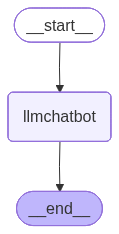

In [7]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [8]:
response = graph.invoke({"messages": [("user", "Hi")]})
response["messages"][-1].content

"It's nice to meet you. Is there something I can help you with or would you like to chat?"

In [9]:
response["messages"][-1].content

"It's nice to meet you. Is there something I can help you with or would you like to chat?"

In [10]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

I'm just a language model, so I don't have emotions or feelings like humans do, but I'm functioning properly and ready to help with any questions or tasks you may have! How can I assist you today?


Chatbot With Tool

In [11]:
from dotenv import load_dotenv
import os

load_dotenv(".env", override=True)

print("key loaded:", bool(os.getenv("TAVILY_API_KEY")))

from langchain_tavily import TavilySearch

tool = TavilySearch(
    max_results=2,
    tavily_api_key=os.getenv("TAVILY_API_KEY")
)

tool.invoke("What is LangGraph")

key loaded: True


{'query': 'What is LangGraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://huggingface.co/learn/agents-course/en/unit2/langgraph/when_to_use_langgraph',
   'title': 'What is LangGraph - Hugging Face',
   'content': '`LangGraph` is a framework developed by LangChain **to manage the control flow of applications that integrate an LLM**. ## Is LangGraph different from LangChain ? The classes from LangChain might be used in LangGraph, but do not HAVE to be used. The packages are different and can be used in isolation, but, in the end, all resources you will find online use both packages hand in hand. `LangGraph` is on the other end of the spectrum, it shines when you need **“Control”** on the execution of your agent. LangGraph is particularly valuable when you need **Control over your applications**. It gives you the tools to build an application that follows a predictable process while still leveraging the power of LLMs. Put simply, if your a

In [12]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b


In [13]:
tools=[tool,multiply]

In [14]:
from langchain_groq import ChatGroq

llm = ChatGroq(model="llama-3.3-70b-versatile")

In [15]:
from dotenv import load_dotenv
import os
from langchain_tavily import TavilySearch

load_dotenv(".env", override=True)

tool = TavilySearch(
    max_results=2,
    tavily_api_key=os.getenv("TAVILY_API_KEY")
)

tools = [tool]

In [16]:
llm_with_tool = llm.bind_tools(tools)
llm_with_tool

_ChatModelBinding(bound=ChatGroq(output_version=None, profile={'max_input_tokens': 131072, 'max_output_tokens': 32768, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True}, client=<groq.resources.chat.completions.Completions object at 0x1110cc9b0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x1113cef90>, model_name='llama-3.3-70b-versatile', model_kwargs={}, groq_api_key=SecretStr('**********'), groq_api_base=None, groq_proxy=None), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-tim

In [17]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

In [18]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]

In [19]:
from dotenv import load_dotenv
import os
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch

load_dotenv(".env", override=True)

llm = ChatGroq(model="llama-3.3-70b-versatile")

tool = TavilySearch(
    max_results=2,
    tavily_api_key=os.getenv("TAVILY_API_KEY")
)

tools = [tool]
llm_with_tool = llm.bind_tools(tools)

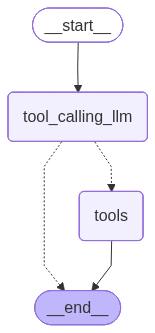

In [20]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [21]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [22]:
response['messages'][-1].content

'{"query": "recent ai news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.securityweek.com/reveng-ai-raises-15-million-to-hunt-for-flaws-and-backdoors-in-software-binaries/amp/", "title": "RevEng.AI Raises $15 Million to Hunt for Flaws and Backdoors in Software Binaries - SecurityWeek", "score": 0.66959417, "published_date": "Wed, 27 May 2026 11:52:55 GMT", "content": "SecurityWeek NewsMay 20, 2026\\n\\n### Cybersecurity Funding\\n\\n## Exaforce Raises $125 Million for Agentic SOC Platform\\n\\nExaforce has raised a total of $200 million and plans on using the latest investment for product development and international expansion.\\n\\nSecurityWeek NewsMay 12, 2026\\n\\n### Artificial Intelligence\\n\\n## White Circle Raises $11 Million for AI Control Platform\\n\\nThe startup will invest in accelerating product development, hiring new talent, and expanding its customer base.\\n\\nIonut ArghireMay 12, 2026\\n\\n### Cybersecurity Funding\\n\

In [23]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (twn82b5gj)
 Call ID: twn82b5gj
  Args:
    query: recent ai news
    search_depth: advanced
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent ai news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.securityweek.com/reveng-ai-raises-15-million-to-hunt-for-flaws-and-backdoors-in-software-binaries/amp/", "title": "RevEng.AI Raises $15 Million to Hunt for Flaws and Backdoors in Software Binaries - SecurityWeek", "score": 0.66959417, "published_date": "Wed, 27 May 2026 11:52:55 GMT", "content": "SecurityWeek NewsMay 20, 2026\n\n### Cybersecurity Funding\n\n## Exaforce Raises $125 Million for Agentic SOC Platform\n\nExaforce ha

In [24]:
response=graph.invoke({"messages":"What is 5 multiplied by 2"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================

I cannot perform this calculation as it requires a mathematical operation rather than a function call. However, I can tell you that 5 multiplied by 2 is 10.


In [25]:
llm.invoke("What is 5 multiplied by 2?").content

'5 multiplied by 2 is 10.'

In [26]:
from langchain_core.tools import tool as lc_tool
from langchain_tavily import TavilySearch
import os

search_tool = TavilySearch(
    max_results=2,
    tavily_api_key=os.getenv("TAVILY_API_KEY")
)

@lc_tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers."""
    return a * b

tools = [search_tool, multiply]

llm_with_tool = llm.bind_tools(tools)

In [27]:
builder = StateGraph(State)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", END)

graph = builder.compile()


In [28]:
response = graph.invoke({
    "messages": [("user", "What is 5 multiplied by 2")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

What is 5 multiplied by 2
================================== Ai Message ==================================
Tool Calls:
  multiply (7ya3x5yzp)
 Call ID: 7ya3x5yzp
  Args:
    a: 5
    b: 2
================================= Tool Message =================================
Name: multiply

10


In [29]:
from langchain_tavily import TavilySearch

search_tool = TavilySearch(
    max_results=2,
    search_depth="advanced",
    topic="news",
    time_range="day",
    tavily_api_key=os.getenv("TAVILY_API_KEY")
)

tools = [search_tool]

llm_with_tool = llm.bind_tools(tools)

In [30]:
builder = StateGraph(State)

builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", END)

graph = builder.compile()

In [31]:
response = graph.invoke({
    "messages": [("user", "Give me the recent ai news")]
})

for message in response["messages"]:
    message.pretty_print()

================================ Human Message =================================

Give me the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (6s5pfps0c)
 Call ID: 6s5pfps0c
  Args:
    query: recent ai news
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent ai news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.securityweek.com/reveng-ai-raises-15-million-to-hunt-for-flaws-and-backdoors-in-software-binaries/amp/", "title": "RevEng.AI Raises $15 Million to Hunt for Flaws and Backdoors in Software Binaries - SecurityWeek", "score": 0.66959417, "published_date": "Wed, 27 May 2026 11:52:55 GMT", "content": "SecurityWeek NewsMay 20, 2026\n\n### Cybersecurity Funding\n\n## Exaforce Raises $125 Million for Agentic SOC Platform\n\nExaforce has raised a total of $200 mi

In [32]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (tj0bm8jwq)
 Call ID: tj0bm8jwq
  Args:
    query: recent ai news
    time_range: day
    topic: news
================================= Tool Message =================================
Name: tavily_search

{"query": "recent ai news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.securityweek.com/reveng-ai-raises-15-million-to-hunt-for-flaws-and-backdoors-in-software-binaries/amp/", "title": "RevEng.AI Raises $15 Million to Hunt for Flaws and Backdoors in Software Binaries - SecurityWeek", "score": 0.66959417, "published_date": "Wed, 27 May 2026 11:52:55 GMT", "content": "SecurityWeek NewsMay 20, 2026\n\n### Cybersecurity Funding\n\n## Exaforce Raises $125 Million for Agentic SOC Platform\n\nExaforce has

In [33]:
from tool_graph_setup import run_demo

response = run_demo("Give me the recent ai news and then multiply 5 by 10")

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (x1xr061yv)
 Call ID: x1xr061yv
  Args:
    query: recent AI news
  multiply (34b75v91g)
 Call ID: 34b75v91g
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.govtech.com/biz/motorola-solutions-sets-up-ai-software-hub-in-boston", "title": "Motorola Solutions Sets Up AI Software ‘Hub’ in Boston - govtech.com", "score": 0.9863631, "published_date": "Wed, 27 May 2026 22:04:32 GMT", "content": "# Motorola Solutions Sets Up AI Software ‘Hub’ in Boston. Motorola Solutions recently bought a company that uses AI to sort non-emergency 911 calls. Motorola Solut

In [34]:
from tool_graph_setup import run_demo

response = run_demo("Give me the recent ai news and then multiply 5 by 10")

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (r0ktvfmbk)
 Call ID: r0ktvfmbk
  Args:
    query: recent AI news
  multiply (rrrrnpb7h)
 Call ID: rrrrnpb7h
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://techcrunch.com/2026/05/27/china-is-increasingly-keeping-its-best-ai-talent-to-itself/", "title": "China is increasingly keeping its best AI talent to itself - TechCrunch", "score": 0.70483154, "published_date": "Wed, 27 May 2026 13:48:41 GMT", "content": "Researchers, startup founders and executives at private firms are now reportedly subject to travel restrictions, with some of the industry’s most 

Adding Memory In Agentic Graph

In [37]:
response=graph.invoke({"messages":"Hello my name is neha"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is neha
================================== Ai Message ==================================

Hello Neha, it's nice to meet you. Is there something I can help you with or would you like to chat?


In [38]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I don't have information about your name. If you'd like to share it, I can try to help with any questions or topics you'd like to discuss.


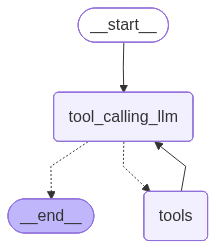

In [39]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [40]:
config={"configurable":{"thread_id":"1"}}

response=graph.invoke({"messages":"Hi my name is neha"},config=config)

response

{'messages': [HumanMessage(content='Hi my name is neha', additional_kwargs={}, response_metadata={}, id='ad9dbdc5-dd30-45ef-a7e2-bd1f234d063b'),
  AIMessage(content="It's nice to meet you, Neha. Is there something I can help you with or would you like to chat?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 26, 'prompt_tokens': 1688, 'total_tokens': 1714, 'completion_time': 0.069520429, 'completion_tokens_details': None, 'prompt_time': 0.085775133, 'prompt_tokens_details': None, 'queue_time': 0.161812135, 'total_time': 0.155295562}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_3272ea2d91', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e6dbd-206f-7f11-a693-db5b3b85867a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1688, 'output_tokens': 26, 'total_tokens': 1714})]}

In [41]:
response['messages'][-1].content

"It's nice to meet you, Neha. Is there something I can help you with or would you like to chat?"

In [42]:
response=graph.invoke({"messages":"Hey what is my name"},config=config)

print(response['messages'][-1].content)

Your name is Neha.


In [43]:
response=graph.invoke({"messages":"Hey do you remember mmy name"},config=config)

print(response['messages'][-1].content)

Yes, I remember your name, it's Neha.


STREAMING

In [44]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

In [45]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

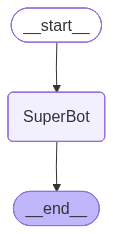

In [46]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [47]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='e54db31b-26a2-4140-a36a-14139c1402c9'),
  AIMessage(content="Hi Krish, nice to meet you. Cricket is an exciting sport, isn't it? Which team or player is your favorite? Do you play cricket yourself or enjoy watching it?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 45, 'total_tokens': 82, 'completion_time': 0.142186825, 'completion_tokens_details': None, 'prompt_time': 0.003954298, 'prompt_tokens_details': None, 'queue_time': 0.458918967, 'total_time': 0.146141123}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_43d97c5965', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e6ebc-b7f2-7631-b48b-4df128c3e3f4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'output_tokens': 37, 'total_tokens': 82})]}

Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.
updates : This streams updates to the state of the graph after each node is called.

In [48]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hi Krish, nice to meet you. Cricket is a fantastic sport, isn't it? Which team or player is your favorite? Are you more into international cricket or do you follow any domestic leagues like the IPL?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 45, 'total_tokens': 89, 'completion_time': 0.159270902, 'completion_tokens_details': None, 'prompt_time': 0.001960166, 'prompt_tokens_details': None, 'queue_time': 0.161091282, 'total_time': 0.161231068}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_45180df409', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e6ebd-2e4c-7db3-9ea5-ec9ac6f155bc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'output_tokens': 44, 'total_tokens': 89})]}}


In [49]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='323ece9a-2c3d-4530-9ae1-028a9951de80'), AIMessage(content="Hi Krish, nice to meet you. Cricket is a fantastic sport, isn't it? Which team or player is your favorite? Are you more into international cricket or do you follow any domestic leagues like the IPL?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 44, 'prompt_tokens': 45, 'total_tokens': 89, 'completion_time': 0.159270902, 'completion_tokens_details': None, 'prompt_time': 0.001960166, 'prompt_tokens_details': None, 'queue_time': 0.161091282, 'total_time': 0.161231068}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_45180df409', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e6ebd-2e4c-7db3-9ea5-ec9ac6f155bc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'outp

In [50]:
# Create a thread
config = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Hi Krish, nice to meet you. Cricket is a fantastic sport, isn't it? Which team or player is your favorite? Do you have a favorite format of the game, like Test matches, ODIs, or T20s?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 49, 'prompt_tokens': 45, 'total_tokens': 94, 'completion_time': 0.137638775, 'completion_tokens_details': None, 'prompt_time': 0.002183875, 'prompt_tokens_details': None, 'queue_time': 0.318849233, 'total_time': 0.13982265}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_ce7bc1685b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e6ebd-642c-7681-8019-e8cc9abc9f7c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'output_tokens': 49, 'total_tokens': 94})]}}


In [51]:
for chunk in graph_builder.stream({'messages':"I also like football"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='4e257bdb-b6a9-440a-a066-645f50b83594'), AIMessage(content="Hi Krish, nice to meet you. Cricket is a fantastic sport, isn't it? Which team or player is your favorite? Do you have a favorite format of the game, like Test matches, ODIs, or T20s?", additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 49, 'prompt_tokens': 45, 'total_tokens': 94, 'completion_time': 0.137638775, 'completion_tokens_details': None, 'prompt_time': 0.002183875, 'prompt_tokens_details': None, 'queue_time': 0.318849233, 'total_time': 0.13982265}, 'model_name': 'llama-3.3-70b-versatile', 'system_fingerprint': 'fp_ce7bc1685b', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019e6ebd-642c-7681-8019-e8cc9abc9f7c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 45, 'output_tokens': 49, 

In [52]:
config = {"configurable": {"thread_id": "5"}}

async for event in graph_builder.astream_events({"messages":["Hi My name is Krish and I like to play cricket"]},config,version="v2"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': ['Hi My name is Krish and I like to play cricket']}}, 'name': 'LangGraph', 'tags': [], 'run_id': '019e6ebd-9c40-7483-81eb-63aa5824fd5a', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi My name is Krish and I like to play cricket', additional_kwargs={}, response_metadata={}, id='3fa8555b-1587-4559-be24-688957ebd7d8')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '019e6ebd-9c42-72d3-8ae8-cd9d039b6db6', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:1fa8cc08-b54d-60f9-8983-178550cea560'}, 'parent_ids': ['019e6ebd-9c40-7483-81eb-63aa5824fd5a']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages':